In [1]:
from pathlib import Path
DATA = Path.cwd().parent / "data"
CSV_DIR = DATA / "csv"
PKL_DIR = DATA / "pickle"

---

In [2]:
import pickle

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

# Pré Processamento

In [3]:
base_train = pd.read_csv(CSV_DIR / 'train.csv')
base_test = pd.read_csv(CSV_DIR / 'test.csv')

### Base de Treino

In [4]:
base_train

,_neutral,browDownLeft,browDownRight,browInnerUp,browOuterUpLeft,browOuterUpRight,cheekPuff,cheekSquintLeft,cheekSquintRight,eyeBlinkLeft,...,lm475_x,lm475_y,lm475_z,lm476_x,lm476_y,lm476_z,lm477_x,lm477_y,lm477_z,emotion
0,1.463337e-06,0.183519,0.166131,0.020736,0.018045,0.011749,0.000014,1.399923e-07,5.695476e-07,0.052206,...,0.337188,-0.396318,0.551493,0.265001,-0.342775,0.551411,0.321846,-0.271198,0.551430,sad
1,2.918669e-06,0.222947,0.093052,0.015815,0.019260,0.046362,0.000020,1.936117e-07,9.618143e-07,0.046785,...,0.382568,-0.478492,0.404535,0.320359,-0.412755,0.404454,0.386279,-0.354671,0.404469,sad
2,1.922390e-06,0.122205,0.140465,0.067447,0.016872,0.011996,0.000011,1.391415e-07,7.295207e-07,0.021820,...,0.423939,-0.335258,0.549592,0.347751,-0.295738,0.549514,0.388248,-0.218024,0.549530,sad
3,2.306581e-06,0.103045,0.224963,0.014049,0.032865,0.009333,0.000016,2.794165e-07,5.399145e-07,0.062335,...,0.280914,-0.459983,0.547021,0.218571,-0.393436,0.546935,0.290319,-0.332992,0.546950,sad
4,2.171917e-07,0.029285,0.004573,0.010991,0.307645,0.393551,0.000016,3.833680e-07,5.567263e-08,0.057022,...,0.001513,-0.628283,0.822519,-0.072322,-0.574405,0.822451,-0.036706,-0.493647,0.822451,sad
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
107842,1.342859e-06,0.111359,0.127140,0.005698,0.024924,0.023592,0.000029,1.489912e-07,3.302426e-07,0.128973,...,0.261139,-0.723919,0.295929,0.207615,-0.644186,0.295840,0.295989,-0.601964,0.295856,neutral
107843,7.755916e-06,0.372895,0.294240,0.000277,0.006054,0.013859,0.000321,7.037571e-07,6.297787e-07,0.276109,...,0.263645,-0.600311,0.375023,0.214457,-0.534062,0.374941,0.287270,-0.498882,0.374954,neutral
107844,2.675677e-06,0.376673,0.385518,0.000286,0.006560,0.005050,0.000059,1.884056e-07,1.357367e-07,0.160007,...,0.463351,-0.397917,0.434505,0.383502,-0.365713,0.434419,0.429618,-0.294365,0.434437,neutral
107845,3.615350e-06,0.455161,0.386288,0.000138,0.004035,0.009451,0.000176,3.366231e-07,3.070228e-07,0.264493,...,0.365293,-0.549294,0.383730,0.303649,-0.489001,0.383649,0.371847,-0.439218,0.383661,neutral


### Base de Teste

In [5]:
base_test

,_neutral,browDownLeft,browDownRight,browInnerUp,browOuterUpLeft,browOuterUpRight,cheekPuff,cheekSquintLeft,cheekSquintRight,eyeBlinkLeft,...,lm475_x,lm475_y,lm475_z,lm476_x,lm476_y,lm476_z,lm477_x,lm477_y,lm477_z,emotion
0,5.903914e-08,0.001103,0.002532,0.444755,0.606037,0.113045,0.000069,1.171760e-07,9.792471e-08,0.090947,...,0.022376,-0.859794,0.755771,-0.070048,-0.795276,0.755634,-0.019577,-0.700549,0.755649,sad
1,4.474211e-06,0.053074,0.057651,0.136090,0.022062,0.019449,0.000054,5.613008e-07,2.085415e-06,0.049822,...,0.414709,-0.387654,0.364470,0.335612,-0.330750,0.364395,0.401975,-0.264414,0.364405,sad
2,1.240546e-06,0.001302,0.001970,0.205246,0.716370,0.553863,0.000014,3.888588e-06,5.133231e-07,0.014268,...,0.278046,-0.571076,0.285311,0.232795,-0.500162,0.285229,0.299714,-0.453425,0.285243,sad
3,5.174078e-07,0.000936,0.000704,0.490462,0.485902,0.463129,0.000040,2.252296e-06,1.972602e-07,0.131371,...,0.163111,-0.487193,0.433627,0.124397,-0.409792,0.433546,0.205245,-0.386068,0.433559,sad
4,1.004335e-06,0.005152,0.007091,0.116430,0.283076,0.317976,0.000071,5.799602e-07,1.234397e-06,0.038554,...,0.399669,-0.637061,0.267637,0.340882,-0.558967,0.267549,0.428468,-0.509253,0.267560,sad
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6743,1.273822e-06,0.002953,0.002908,0.217938,0.540980,0.369998,0.000145,5.826306e-07,1.405860e-06,0.007531,...,0.391550,-0.279764,0.485028,0.327278,-0.236102,0.484954,0.376128,-0.175003,0.484968,neutral
6744,3.376147e-06,0.082213,0.058085,0.060658,0.029211,0.063582,0.000009,2.517584e-07,5.827812e-07,0.302867,...,0.328533,-0.578936,0.333190,0.277659,-0.503578,0.333089,0.364946,-0.464601,0.333104,neutral
6745,4.504793e-07,0.001365,0.024466,0.013597,0.610641,0.085456,0.000015,2.883541e-07,1.204305e-07,0.021193,...,0.281998,-0.572742,0.428820,0.211990,-0.504562,0.428738,0.285013,-0.443800,0.428752,neutral
6746,6.139216e-07,0.002885,0.001087,0.165135,0.346564,0.453466,0.000213,7.811572e-07,4.480265e-07,0.680701,...,0.197910,-0.564932,0.315362,0.157780,-0.493026,0.315267,0.233730,-0.463963,0.315274,neutral


# Visualização dos dados

Exibindo o nome das categorias de tipo de emoção e sua frequência.

In [6]:
np.unique(base_train['emotion'], return_counts=True)

(array(['angry', 'disgusted', 'fearful', 'happy', 'neutral', 'sad',
        'surprised'], dtype=object),
 array([14497,  1601, 15057, 28051, 19239, 17187, 12215]))

In [7]:
np.unique(base_test['emotion'], return_counts=True)

(array(['angry', 'disgusted', 'fearful', 'happy', 'neutral', 'sad',
        'surprised'], dtype=object),
 array([ 865,  102,  939, 1729, 1194, 1116,  803]))

---

### Gráfico da Base Treino

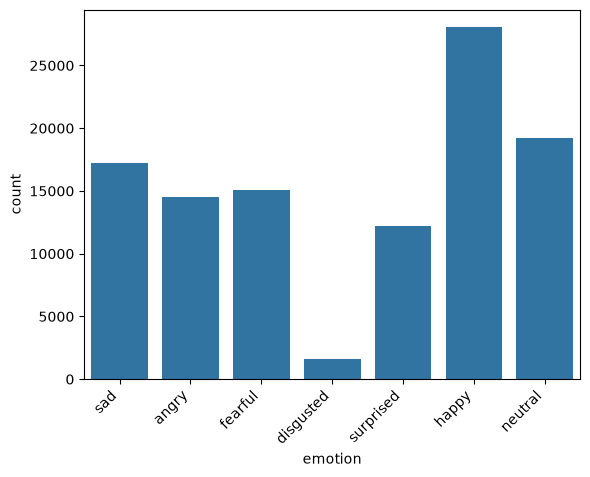

In [8]:
sns.countplot(x=base_train['emotion'])
# Mantenha a próxima linha para rotacionar os rótulos e facilitar sua leitura
plt.xticks(rotation=45, ha='right');

### Grafico da Base Teste

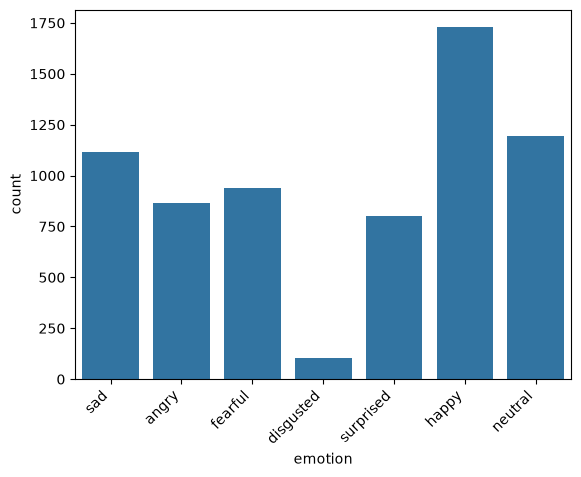

In [9]:
sns.countplot(x=base_test['emotion'])
# Mantenha a próxima linha para rotacionar os rótulos e facilitar sua leitura
plt.xticks(rotation=45, ha='right');

## Divisão entre previsores e classe

In [10]:
X_train = base_train.iloc[:, :-1].values
X_train

array([[ 1.46333720e-06,  1.83518840e-01,  1.66131440e-01, ...,
         3.21846500e-01, -2.71197700e-01,  5.51429800e-01],
       [ 2.91866920e-06,  2.22946600e-01,  9.30520400e-02, ...,
         3.86279080e-01, -3.54670800e-01,  4.04468950e-01],
       [ 1.92238990e-06,  1.22205265e-01,  1.40465400e-01, ...,
         3.88248300e-01, -2.18023510e-01,  5.49529730e-01],
       ...,
       [ 2.67567700e-06,  3.76672500e-01,  3.85518160e-01, ...,
         4.29617640e-01, -2.94365470e-01,  4.34437000e-01],
       [ 3.61535040e-06,  4.55160560e-01,  3.86287750e-01, ...,
         3.71846650e-01, -4.39217540e-01,  3.83661300e-01],
       [ 7.32907400e-06,  2.53492830e-01,  2.19230300e-01, ...,
         2.03336820e-01, -5.45525100e-01,  3.66558100e-01]])

In [11]:
y_train = base_train.iloc[:, -1].values
y_train

<StringArray>
[    'sad',     'sad',     'sad',     'sad',     'sad',     'sad',     'sad',
     'sad',     'sad',     'sad',
 ...
 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral',
 'neutral', 'neutral', 'neutral']
Length: 107847, dtype: str

In [12]:
X_test = base_test.iloc[:, :-1].values
X_test

array([[ 5.9039138e-08,  1.1032809e-03,  2.5318353e-03, ...,
        -1.9577360e-02, -7.0054920e-01,  7.5564920e-01],
       [ 4.4742110e-06,  5.3073745e-02,  5.7650954e-02, ...,
         4.0197527e-01, -2.6441392e-01,  3.6440483e-01],
       [ 1.2405465e-06,  1.3018624e-03,  1.9698914e-03, ...,
         2.9971370e-01, -4.5342463e-01,  2.8524283e-01],
       ...,
       [ 4.5047932e-07,  1.3654669e-03,  2.4465991e-02, ...,
         2.8501284e-01, -4.4379950e-01,  4.2875177e-01],
       [ 6.1392160e-07,  2.8854737e-03,  1.0867500e-03, ...,
         2.3373035e-01, -4.6396253e-01,  3.1527433e-01],
       [ 4.4265065e-07,  2.3434184e-01,  2.5459757e-01, ...,
         3.8248610e-01, -4.5235816e-01,  2.6386008e-01]])

In [13]:
y_test = base_test.iloc[:, -1].values
y_test

<StringArray>
[    'sad',     'sad',     'sad',     'sad',     'sad',     'sad',     'sad',
     'sad',     'sad',     'sad',
 ...
 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral',
 'neutral', 'neutral', 'neutral']
Length: 6748, dtype: str

## Tratamento da variável alvo

In [14]:
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train)
y_test = label_encoder.fit_transform(y_test)

In [15]:
y_train

array([5, 5, 5, ..., 4, 4, 4])

In [16]:
y_test

array([5, 5, 5, ..., 4, 4, 4])

## Salvar as variáveis

In [17]:
with open(PKL_DIR / "expressions.pkl", "wb") as f:
    pickle.dump((X_train, y_train, X_test, y_test), f)